<a href="https://colab.research.google.com/github/nabelaislam-dev/nabela-islam/blob/main/MachineLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Machine Learning Project - Mashroom Classification

Predicting whether a mashroom is poisonous (p) or edible (e) analysing datas of their physical traits.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, roc_curve, roc_auc_score, adjusted_rand_score)

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

1. Dataset Description

1.1 Load data

In [ ]:
df = pd.read_csv("mushroom_dataset.csv", sep=";")
print("Shape:", df.shape)
df.head()


Shape: (61069, 21)


,class,cap-diameter,cap-shape,cap-surface,cap-color,does-bruise-or-bleed,gill-attachment,gill-spacing,gill-color,stem-height,stem-width,stem-root,stem-surface,stem-color,veil-type,veil-color,has-ring,ring-type,spore-print-color,habitat,season
0,p,15.26,x,g,o,f,e,NaN,w,16.95,17.09,s,y,w,u,w,t,g,NaN,d,w
1,p,16.60,x,g,o,f,e,NaN,w,17.99,18.19,s,y,w,u,w,t,g,NaN,d,u
2,p,14.07,x,g,o,f,e,NaN,w,17.80,17.74,s,y,w,u,w,t,g,NaN,d,w
3,p,14.17,f,h,e,f,e,NaN,w,15.77,15.98,s,y,w,u,w,t,p,NaN,d,w
4,p,14.64,x,h,o,f,e,NaN,w,16.53,17.20,s,y,w,u,w,t,p,NaN,d,w


1.2 Feature Details

In [ ]:
print(f"Number of data points (rows): {df.shape[0]}")
print(f"Number of columns (features + target): {df.shape[1]}")
print(f"Number of input features: {df.shape[1] - 1}\n")

print("Data types:")
print(df.dtypes)

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = [c for c in df.columns if c not in numeric_cols and c != 'class']

print(f"\nQuantitative (numeric) features ({len(numeric_cols)}): {numeric_cols}")
print(f"Categorical features ({len(categorical_cols)}): {categorical_cols}")


Number of data points (rows): 61069
Number of columns (features + target): 21
Number of input features: 20

Data types:
class                    object
cap-diameter            float64
cap-shape                object
cap-surface              object
cap-color                object
does-bruise-or-bleed     object
gill-attachment          object
gill-spacing             object
gill-color               object
stem-height             float64
stem-width              float64
stem-root                object
stem-surface             object
stem-color               object
veil-type                object
veil-color               object
has-ring                 object
ring-type                object
spore-print-color        object
habitat                  object
season                   object
dtype: object

Quantitative (numeric) features (3): ['cap-diameter', 'stem-height', 'stem-width']
Categorical features (17): ['cap-shape', 'cap-surface', 'cap-color', 'does-bruise-or-bleed', 'gill-attachment'

This is a Classification problem, not regression, because the target column class only takes two discrete values, which are p (poisonous) and e (edible) rather than a continuous numeric quantity.

1.3 Missing Values

In [ ]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_summary = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
missing_summary = missing_summary[missing_summary["missing_count"] > 0].sort_values("missing_pct", ascending=False)
missing_summary

,missing_count,missing_pct
veil-type,57892,94.80
spore-print-color,54715,89.60
veil-color,53656,87.86
stem-root,51538,84.39
stem-surface,38124,62.43
gill-spacing,25063,41.04
cap-surface,14120,23.12
gill-attachment,9884,16.18
ring-type,2471,4.05


1.4 Correlation Heatmap

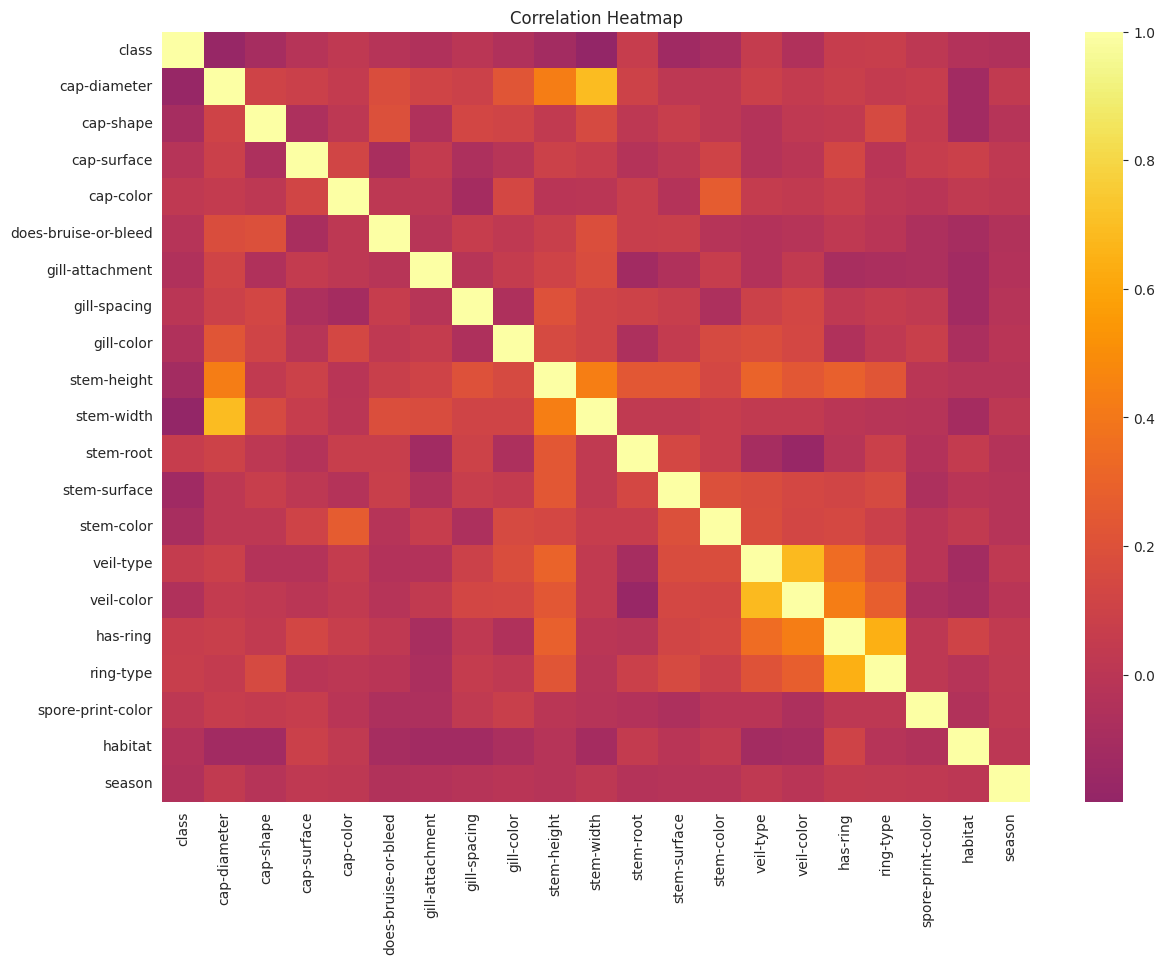

In [ ]:
from sklearn.preprocessing import LabelEncoder

corr_df = df.copy()
for col in corr_df.columns:
    if not pd.api.types.is_numeric_dtype(corr_df[col]):
        corr_df[col] = corr_df[col].fillna("missing")
        corr_df[col] = LabelEncoder().fit_transform(corr_df[col])

plt.figure(figsize=(14, 10))
sns.heatmap(corr_df.corr(), cmap="inferno", center=0, annot=False)
plt.title("Correlation Heatmap")
plt.show()


1.5 Imbalance data set check


class
p    33888
e    27181
Name: count, dtype: int64

Percentage split:
class
p    55.49
e    44.51
Name: count, dtype: float64


/tmp/ipykernel_2499/2041539103.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='class', data=df, palette="plasma")


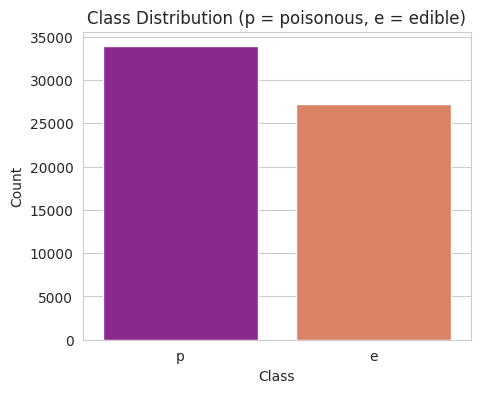

In [ ]:
class_counts = df['class'].value_counts()
print(class_counts)
print(f"\nPercentage split:\n{(class_counts / len(df) * 100).round(2)}")

plt.figure(figsize=(5, 4))
sns.countplot(x='class', data=df, palette="plasma")
plt.title("Class Distribution (p = poisonous, e = edible)")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

1.6 Exploratory Data Analysis (EDA)

/tmp/ipykernel_2499/1062170451.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='class', y=col, data=df, ax=ax, palette="inferno")
/tmp/ipykernel_2499/1062170451.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='class', y=col, data=df, ax=ax, palette="inferno")
/tmp/ipykernel_2499/1062170451.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='class', y=col, data=df, ax=ax, palette="inferno")


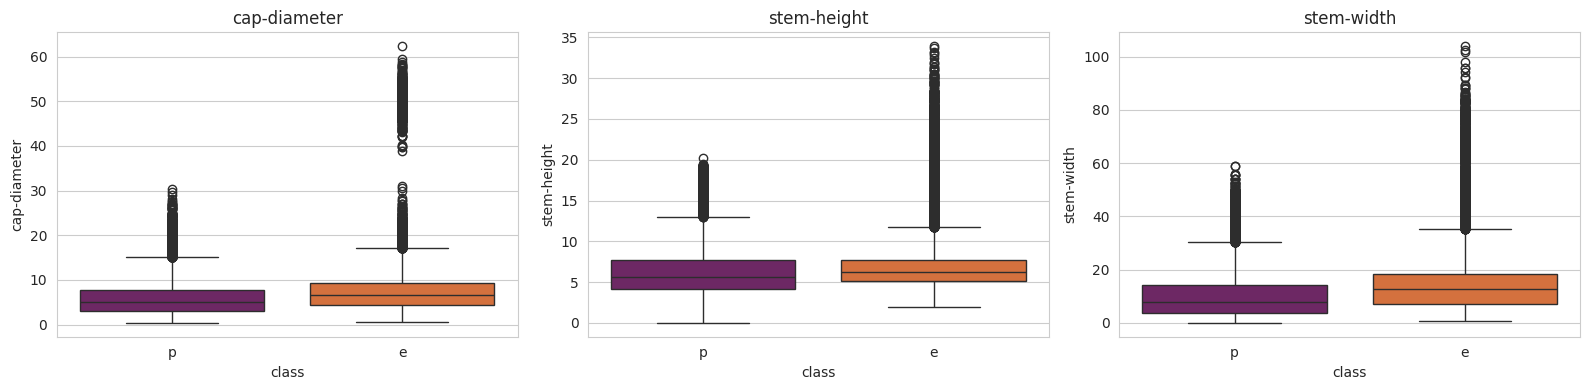

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(x='class', y=col, data=df, ax=ax, palette="inferno")
    ax.set_title(col)
plt.tight_layout()
plt.show()


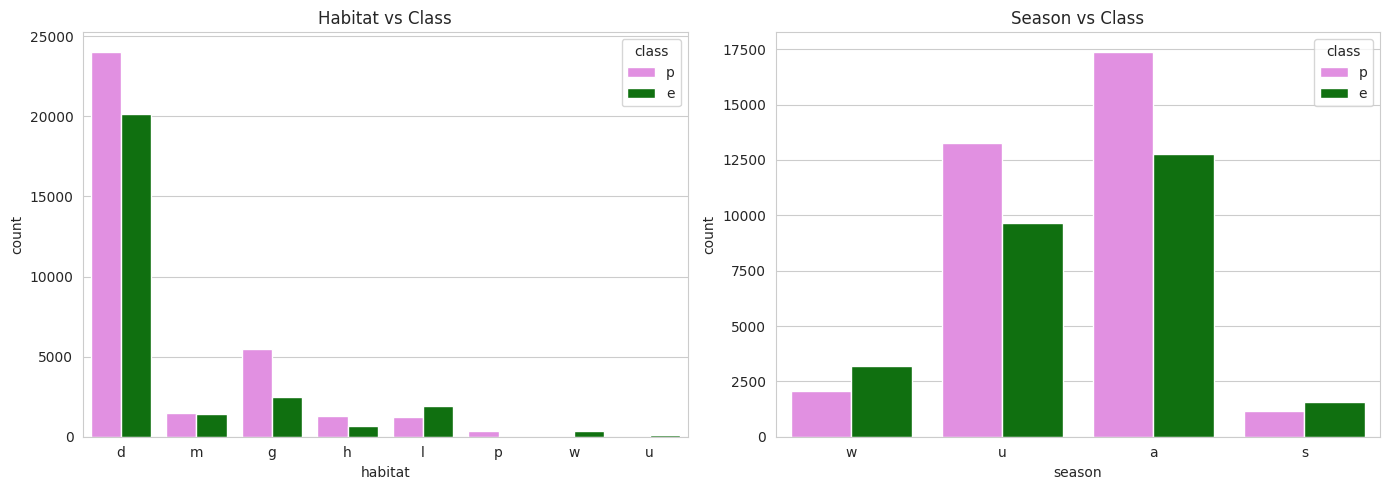

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(x='habitat', hue='class', data=df, ax=axes[0], palette={'e': 'green', 'p': 'violet'})
axes[0].set_title("Habitat vs Class")
sns.countplot(x='season', hue='class', data=df, ax=axes[1], palette={'e': 'green', 'p': 'violet'})
axes[1].set_title("Season vs Class")
plt.tight_layout()
plt.show()

2. Dataset Processing

2.1 Problem 1 : Missing values

In [ ]:
cols_to_drop = ['veil-type', 'spore-print-color', 'veil-color', 'stem-root', 'stem-surface']
df_clean = df.drop(columns=cols_to_drop)

cols_to_impute = ['gill-spacing', 'cap-surface', 'gill-attachment', 'ring-type']
for col in cols_to_impute:
    mode_value = df_clean[col].mode()[0]
    df_clean[col] = df_clean[col].fillna(mode_value)

print("Remaining missing values:\n", df_clean.isnull().sum().sum(), "total")
print("New shape:", df_clean.shape)

Remaining missing values:
 0 total
New shape: (61069, 16)


2.2 Problem 2 : Encoding catagorial values

In [ ]:
y = df_clean['class'].map({'p': 1, 'e': 0})

feature_cols = [c for c in df_clean.columns if c != 'class']
cat_feature_cols = [c for c in feature_cols if c not in numeric_cols]

X = pd.get_dummies(df_clean[feature_cols], columns=cat_feature_cols, drop_first=True)

print("Shape after one-hot encoding:", X.shape)
print(f"(Started with {len(feature_cols)} feature columns, expanded to {X.shape[1]} after one-hot encoding)")


Shape after one-hot encoding: (61069, 80)
(Started with 15 feature columns, expanded to 80 after one-hot encoding)


2.3 Dataset Splitting

We split into train (80%) and test (20%) sets.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print("\nTrain class balance:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class balance:\n", y_test.value_counts(normalize=True).round(3))


Train shape: (48855, 80)  Test shape: (12214, 80)

Train class balance:
 class
1    0.555
0    0.445
Name: proportion, dtype: float64

Test class balance:
 class
1    0.555
0    0.445
Name: proportion, dtype: float64


In [ ]:
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])


4. Model training and testing


4.1 Model 1 : KNN

In [ ]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
knn_pred = knn.predict(X_test_scaled)
knn_proba = knn.predict_proba(X_test_scaled)[:, 1]

4.2 Model 2 : Decision tree

In [ ]:
dt = DecisionTreeClassifier(max_depth=10, random_state=42)
dt.fit(X_train_scaled, y_train)
dt_pred = dt.predict(X_test_scaled)
dt_proba = dt.predict_proba(X_test_scaled)[:, 1]


4.3 Model 3 : Logistic Regression

In [ ]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_scaled, y_train)
lr_pred = log_reg.predict(X_test_scaled)
lr_proba = log_reg.predict_proba(X_test_scaled)[:, 1]


4.4 Model 4 : Naive Bayes

In [ ]:
nb = GaussianNB()
nb.fit(X_train_scaled, y_train)
nb_pred = nb.predict(X_test_scaled)
nb_proba = nb.predict_proba(X_test_scaled)[:, 1]


4.5 Model 5 : Neural Network

In [ ]:
mlp = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, random_state=42)
mlp.fit(X_train_scaled, y_train)
mlp_pred = mlp.predict(X_test_scaled)
mlp_proba = mlp.predict_proba(X_test_scaled)[:, 1]


4.6 Model 6 : K-means (unsupervised)

In [ ]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_train_scaled)

comparison = pd.crosstab(cluster_labels, y_train, rownames=['Cluster'], colnames=['True Class'])
print(comparison)

ari = adjusted_rand_score(y_train, cluster_labels)
print(f"\nAdjusted Rand Index (agreement with true labels): {ari:.4f}")


True Class      0      1
Cluster                 
0           13798  20049
1            7947   7061

Adjusted Rand Index (agreement with true labels): 0.0196


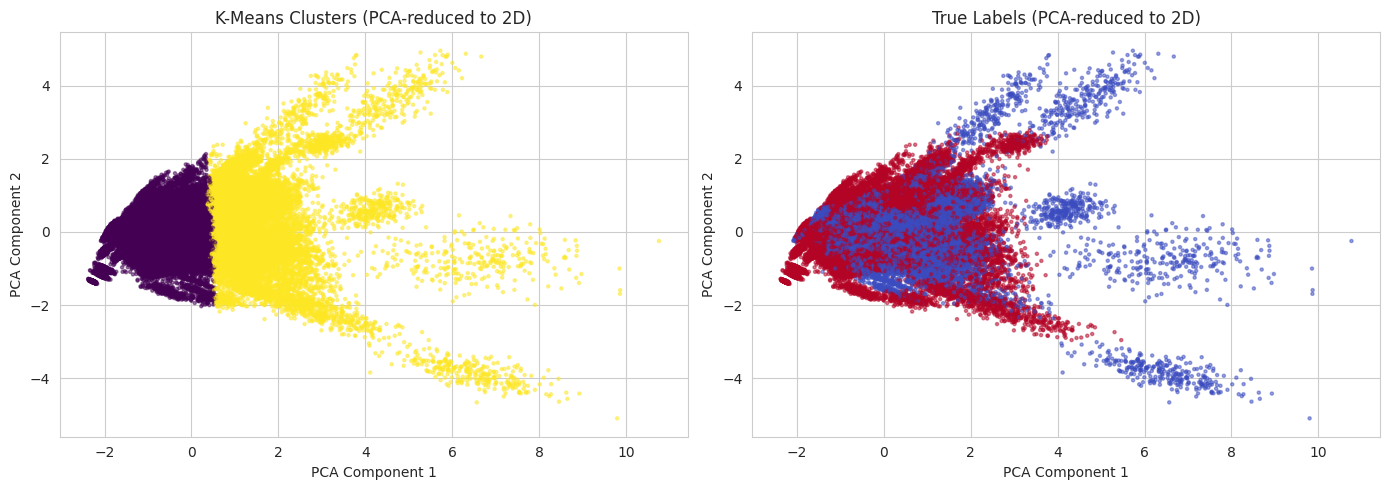

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap='viridis', s=5, alpha=0.5)
axes[0].set_title("K-Means Clusters (PCA-reduced to 2D)")
axes[0].set_xlabel("PCA Component 1")
axes[0].set_ylabel("PCA Component 2")

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=y_train, cmap='coolwarm', s=5, alpha=0.5)
axes[1].set_title("True Labels (PCA-reduced to 2D)")
axes[1].set_xlabel("PCA Component 1")
axes[1].set_ylabel("PCA Component 2")

plt.tight_layout()
plt.show()

5. Model Comparison Analysis

In [ ]:
results = {
    'KNN': (knn_pred, knn_proba),
    'Decision Tree': (dt_pred, dt_proba),
    'Logistic Regression': (lr_pred, lr_proba),
    'Naive Bayes': (nb_pred, nb_proba),
    'Neural Network': (mlp_pred, mlp_proba),
}

from sklearn.metrics import classification_report

for name, (pred, proba) in results.items():
    print(f"--- {name} ---")
    print(classification_report(y_test, pred, target_names=['edible', 'poisonous']))
    print()

metrics_table = []
for name, (pred, proba) in results.items():
    metrics_table.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'AUC': roc_auc_score(y_test, proba),
    })

metrics_df = pd.DataFrame(metrics_table).set_index('Model').round(4)
metrics_df


--- KNN ---
              precision    recall  f1-score   support

      edible       1.00      1.00      1.00      5436
   poisonous       1.00      1.00      1.00      6778

    accuracy                           1.00     12214
   macro avg       1.00      1.00      1.00     12214
weighted avg       1.00      1.00      1.00     12214


--- Decision Tree ---
              precision    recall  f1-score   support

      edible       0.80      0.94      0.87      5436
   poisonous       0.94      0.82      0.88      6778

    accuracy                           0.87     12214
   macro avg       0.87      0.88      0.87     12214
weighted avg       0.88      0.87      0.87     12214


--- Logistic Regression ---
              precision    recall  f1-score   support

      edible       0.75      0.75      0.75      5436
   poisonous       0.80      0.80      0.80      6778

    accuracy                           0.78     12214
   macro avg       0.78      0.78      0.78     12214
weighted a

,Accuracy,Precision,Recall,F1,AUC
Model,,,,,
KNN,1.0000,1.0000,1.0000,1.0000,1.0000
Decision Tree,0.8706,0.9418,0.8172,0.8751,0.9587
Logistic Regression,0.7778,0.8014,0.7971,0.7993,0.8578
Naive Bayes,0.6798,0.8150,0.5472,0.6548,0.7719
Neural Network,1.0000,1.0000,1.0000,1.0000,1.0000


5.1 Accuracy Comparison (Bar Chart)

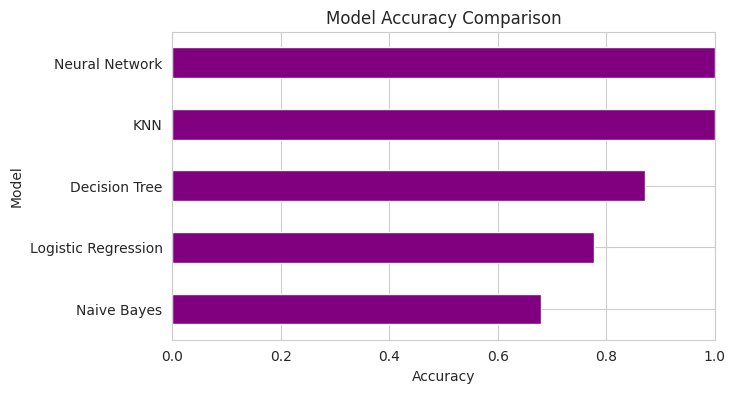

In [ ]:
metrics_df['Accuracy'].sort_values().plot(kind='barh', figsize=(7, 4), color='purple')
plt.title("Model Accuracy Comparison")
plt.xlabel("Accuracy")
plt.xlim(0, 1)
plt.show()


5.2 Precision & Recall comparison

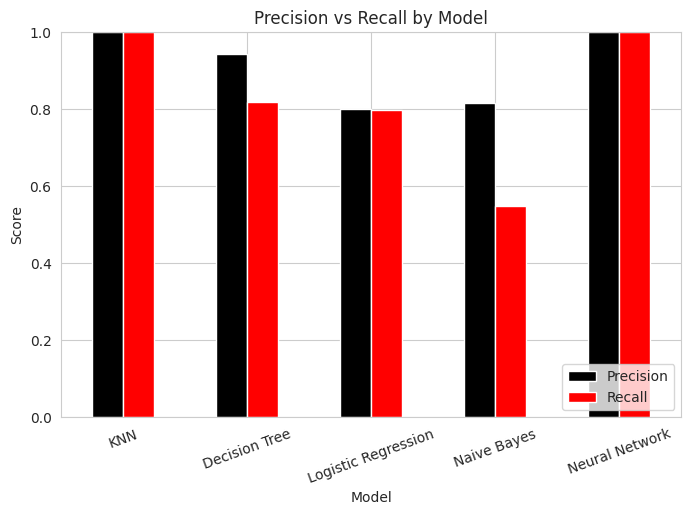

In [ ]:
metrics_df[['Precision', 'Recall']].plot(kind='bar', figsize=(8, 5), color=['black', 'red'])
plt.title("Precision vs Recall by Model")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.show()


5.3 Confusion matrices

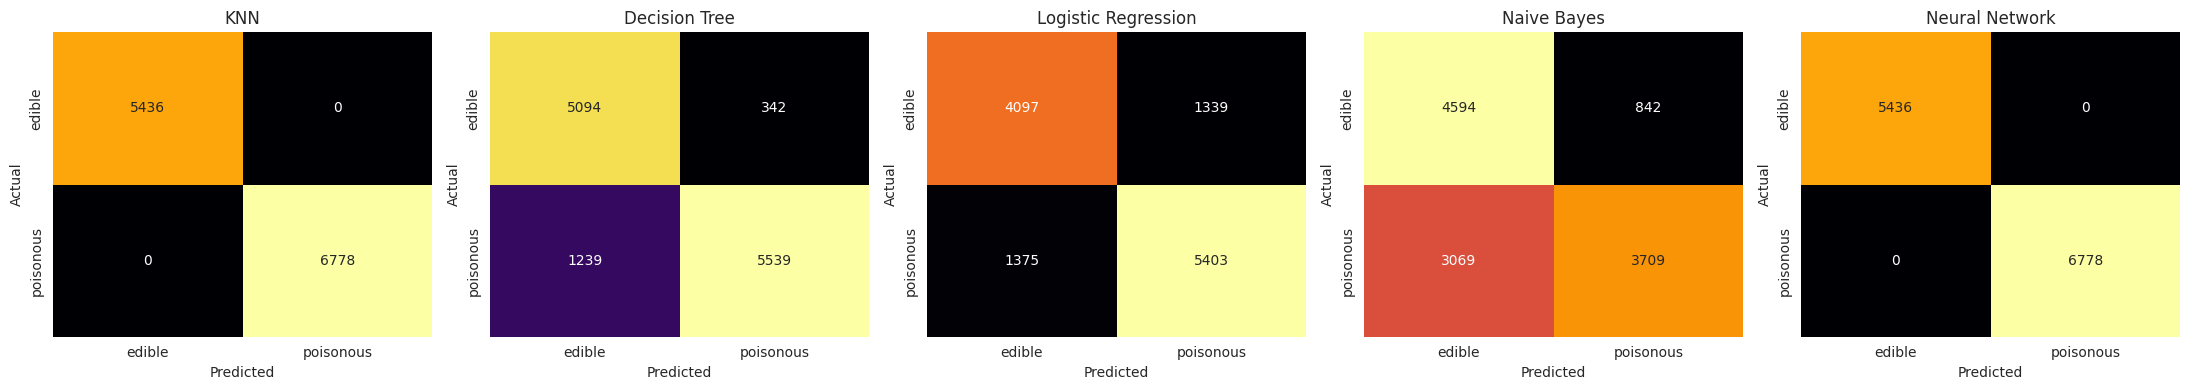

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, (pred, proba)) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='inferno', ax=ax, cbar=False,
                xticklabels=['edible', 'poisonous'], yticklabels=['edible', 'poisonous'])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()


5.4 ROC curves & AUC

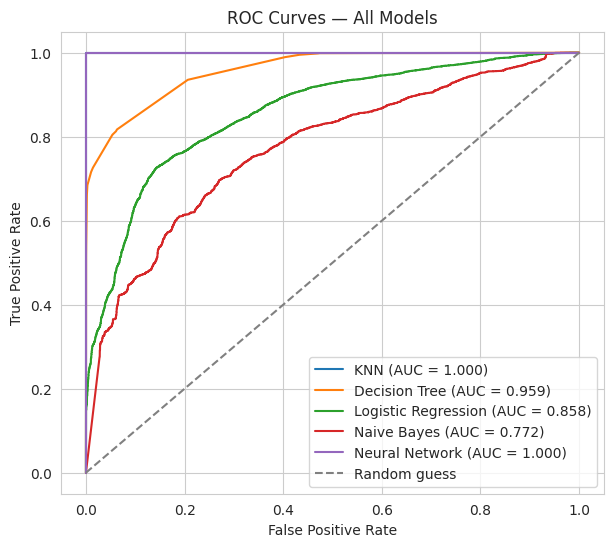

In [ ]:
plt.figure(figsize=(7, 6))
for name, (pred, proba) in results.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — All Models")
plt.legend(loc='lower right')
plt.show()


In [ ]:
from sklearn.model_selection import cross_val_score

cv_models = {
    'KNN': knn,
    'Decision Tree': dt,
    'Logistic Regression': log_reg,
    'Naive Bayes': nb,
    'Neural Network': mlp,
}

print("10-Fold Cross-Validation Accuracy:")
print("-" * 40)
for name, model in cv_models.items():
    scores = cross_val_score(model, X_train_scaled, y_train, cv=10, scoring='accuracy')
    print(f"{name}: {scores.mean():.4f} (+/- {scores.std():.4f})")

10-Fold Cross-Validation Accuracy:
----------------------------------------
KNN: 0.9999 (+/- 0.0001)
Decision Tree: 0.8734 (+/- 0.0092)
Logistic Regression: 0.7777 (+/- 0.0052)
Naive Bayes: 0.6783 (+/- 0.0041)
Neural Network: 0.9997 (+/- 0.0003)
